(sec-9-1)=
# 9.1 Linear-Phase FIR Filters

Removing noise from an ECG is useful only if we also understand what happens to the heartbeat's shape and timing. A linear-phase FIR filter delays frequency components by the same amount wherever its response has a fixed sign and is nonzero. This gives us a predictable delay to account for when comparing waveforms.

I will start with the weighted sum that defines an FIR filter, then show how symmetry in its coefficients leads to linear phase. We will check the result in Python and compare filtered ECGs, paying attention to both smoothing and delay.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-9-1-1)=
## 9.1.1 Finite Impulse Response Filters

A causal FIR filter of **order** $M$ computes each output sample as a weighted sum of the current input sample and the $M$ previous ones:

(eq-9-1)=
\begin{equation*}
y[n] = \sum_{k=0}^{M} b_k\, x[n-k] = b_0\,x[n] + b_1\,x[n-1] + \cdots + b_M\,x[n-M]. \tag{9.1}
\end{equation*}

The index $k$ counts how far back we look from the current sample. The coefficient $b_0$ weights the current value, $b_1$ weights the previous one, and so on. There are $M+1$ coefficients for an order-$M$ filter. For $M=2$ and all three coefficients equal to $1/3$, the equation becomes a three-sample moving average. The symmetry of those weights will matter when we discuss phase.

There is no feedback, because past outputs never enter the sum. If we feed in a unit impulse, $x[n] = \delta[n]$, then $\delta[n-k]$ is nonzero only when $k = n$, so the output is $y[n] = b_n$ for $0 \le n \le M$ and zero everywhere else. The impulse response *is* the list of coefficients,

$$
h[n] = \begin{cases} b_n, & 0 \le n \le M,\\ 0, & \text{otherwise,}\end{cases}
$$

and it has the finite **length** $N = M + 1$ that gives the filter its name. Equation [(9.1)](#eq-9-1) is then nothing more than the convolution sum $y = x * h$ of [Section 4.2](../ch05_convolution/02_convolution_sum.ipynb) with a kernel of $N$ samples. Throughout this chapter $M$ denotes the order and $N = M+1$ the number of coefficients, or **taps**.

Taking the z-transform of the impulse response gives the transfer function

(eq-9-2)=
\begin{equation*}
H(z) = \sum_{n=0}^{M} h[n]\, z^{-n} = \frac{h[0]\,z^{M} + h[1]\,z^{M-1} + \cdots + h[M]}{z^{M}}. \tag{9.2}
\end{equation*}

The second form, obtained by multiplying the numerator and the denominator by $z^M$, shows that the denominator is simply $z^M$: all $M$ poles sit at the origin. The origin lies inside the unit circle, so an FIR filter is stable for *any* choice of coefficients (Section 11.3). The same conclusion follows in the time domain, since the stability condition $\sum_n |h[n]| < \infty$ is a finite sum of finite numbers. Evaluating $H(z)$ on the unit circle, $z = e^{j\Omega}$, gives the frequency response

(eq-9-3)=
\begin{equation*}
H(e^{j\Omega}) = \sum_{n=0}^{M} h[n]\, e^{-j\Omega n}. \tag{9.3}
\end{equation*}

Equation [(9.1)](#eq-9-1) translates almost word for word into NumPy. The function below loops over the $M+1$ taps and, for each tap, adds a scaled and shifted copy of the whole input to the output. We compare it with the two library routines that compute the same thing: `np.convolve`, which returns the full convolution of length $L + M$ for an input of length $L$, and `scipy.signal.lfilter`, which returns the first $L$ samples and is the usual way to run a causal filter.

In [2]:
def fir_direct(h, x):
    """Causal FIR filter computed from the difference equation (14.1)."""
    y = np.zeros(len(x))
    for k, hk in enumerate(h):
        y[k:] += hk * x[: len(x) - k]
    return y


h = np.array([1, 2, 3, 2, 1]) / 9      # a short symmetric smoother, M = 4
x = rng.normal(size=1000)

y_direct = fir_direct(h, x)
y_conv = np.convolve(x, h)[: len(x)]   # keep the first L samples of the full convolution
y_lfilter = signal.lfilter(h, 1.0, x)

print(f"max |direct - np.convolve| = {np.max(np.abs(y_direct - y_conv)):.2e}")
print(f"max |direct - lfilter|     = {np.max(np.abs(y_direct - y_lfilter)):.2e}")
print(f"poles of H(z): {np.roots(np.r_[1.0, np.zeros(len(h) - 1)])}")

max |direct - np.convolve| = 4.44e-16
max |direct - lfilter|     = 4.44e-16
poles of H(z): [0. 0. 0. 0.]


(sec-9-1-2)=
## 9.1.2 What Linear Phase Buys Us

Suppose the frequency response of a filter can be written as

(eq-9-4)=
\begin{equation*}
H(e^{j\Omega}) = A(\Omega)\, e^{-j\alpha\Omega}, \tag{9.4}
\end{equation*}

where $A(\Omega)$ is a *real-valued* function, called the **amplitude response**, and $\alpha$ is a constant. Feed in a sinusoid $x[n] = \cos(\Omega_0 n + \theta)$. As shown in Section 8.4, an LTI system multiplies the amplitude of a sinusoid by $|H(e^{j\Omega_0})|$ and adds $\angle H(e^{j\Omega_0})$ to its phase. If $A(\Omega_0) > 0$, then $|H| = A(\Omega_0)$ and $\angle H = -\alpha\Omega_0$, so

$$
\begin{aligned}
y[n] &= A(\Omega_0)\cos(\Omega_0 n + \theta - \alpha\Omega_0) \\
     &= A(\Omega_0)\cos\big(\Omega_0 (n - \alpha) + \theta\big).
\end{aligned}
$$

The second line is the input scaled by $A(\Omega_0)$ and delayed by $\alpha$ samples, and the delay does *not* depend on $\Omega_0$. A real signal is a superposition of many such sinusoids. If all of them lie in the passband, where $A(\Omega) \approx 1$, superposition gives

$$
y[n] \approx x[n - \alpha],
$$

a delayed but undistorted copy of the input. With a general phase response $\varphi(\Omega)$ the component at $\Omega_0$ would instead be delayed by the phase delay $-\varphi(\Omega_0)/\Omega_0$, which changes from one frequency to the next unless $\varphi$ is a straight line through the origin. For the phase $\varphi(\Omega) = -\alpha\Omega$, both the phase delay and the group delay $-d\varphi/d\Omega$ of [Section 13.2](../ch13_filter_fundamentals/index.md) equal $\alpha$ at every frequency.

What if $A(\Omega_0)$ is negative? We can write $A = |A|\,e^{j\pi}$, which adds $\pi$ to the phase. The phase therefore jumps by $\pi$ wherever $A(\Omega)$ changes sign, but between jumps it is still the same straight line. For a well-designed filter the sign changes happen only in the stopband, where the output is negligible anyway. Filters of the form

$$
H(e^{j\Omega}) = A(\Omega)\, e^{j(\beta - \alpha\Omega)}, \qquad A(\Omega)\ \text{real},
$$

are said to have **generalized linear phase**. The extra constant $\beta$ will be $0$ or $\pi/2$ for the filters in this chapter. A constant phase offset does not change the group delay, which remains $\alpha$.

(sec-9-1-3)=
## 9.1.3 Symmetry Implies Linear Phase

Consider an FIR filter whose order $M$ is even and whose coefficients are mirror images about the center sample $n = M/2$:

(eq-9-5)=
\begin{equation*}
h[n] = h[M - n], \qquad n = 0, 1, \ldots, M. \tag{9.5}
\end{equation*}

The smoother `h = [1, 2, 3, 2, 1]/9` from the previous code cell is an example with $M = 4$. We now show that every such filter has the form [(9.4)](#eq-9-4).

**Step 1: factor out the delay to the center.** Multiplying and dividing each term of [(9.3)](#eq-9-3) by $e^{-j\Omega M/2}$,

$$
H(e^{j\Omega}) = e^{-j\Omega M/2} \sum_{n=0}^{M} h[n]\, e^{j\Omega (M/2 - n)}.
$$

The exponent $M/2 - n$ measures the distance of sample $n$ from the center: positive to the left of it, negative to the right.

**Step 2: split the sum around the center.** We separate the center term $n = M/2$, the left half $n < M/2$ and the right half $n > M/2$:

$$
\sum_{n=0}^{M} h[n]\, e^{j\Omega (M/2 - n)} = h[M/2] + \sum_{n=0}^{M/2-1} h[n]\, e^{j\Omega (M/2 - n)} + \sum_{n=M/2+1}^{M} h[n]\, e^{j\Omega (M/2 - n)} .
$$

**Step 3: fold the right half onto the left half.** In the last sum we substitute $n = M - m$. As $n$ runs from $M/2 + 1$ up to $M$, the new index $m$ runs from $M/2 - 1$ down to $0$. The exponent becomes $M/2 - (M - m) = -(M/2 - m)$, and the symmetry [(9.5)](#eq-9-5) replaces $h[M-m]$ by $h[m]$:

$$
\sum_{n=M/2+1}^{M} h[n]\, e^{j\Omega (M/2 - n)} = \sum_{m=0}^{M/2-1} h[m]\, e^{-j\Omega (M/2 - m)} .
$$

**Step 4: combine each pair of exponentials into a cosine.** Renaming $m$ back to $n$, the left and right halves now run over the same indices with exponents of opposite sign. Euler's relation $e^{j\theta} + e^{-j\theta} = 2\cos\theta$ from [Section 2.1](../ch02_math_toolkit/01_complex_numbers.ipynb) gives

$$
H(e^{j\Omega}) = e^{-j\Omega M/2} \left[ h[M/2] + \sum_{n=0}^{M/2-1} 2\,h[n] \cos\!\big(\Omega(M/2 - n)\big) \right].
$$

**Step 5: re-index by the distance from the center.** With $k = M/2 - n$, which runs from $M/2$ down to $1$,

(eq-9-6)=
\begin{equation*}
H(e^{j\Omega}) = e^{-j\Omega M/2} A(\Omega), \qquad A(\Omega) = h[M/2] + 2\sum_{k=1}^{M/2} h[M/2 - k]\cos(k\Omega). \tag{9.6}
\end{equation*}

The amplitude response $A(\Omega)$ is a sum of cosines with real coefficients, so it is real for every $\Omega$. Equation [(9.6)](#eq-9-6) is exactly the linear-phase form [(9.4)](#eq-9-4) with $\alpha = M/2$. Every symmetric filter of even order has linear phase, and its delay is half its order. Notice also that the symmetry halved the number of free parameters: $A(\Omega)$ is determined by the $M/2 + 1$ coefficients $h[0], \ldots, h[M/2]$.

**Example 9.1.1.** Find the amplitude response of $h = [1, 2, 3, 2, 1]/9$.

Here $M = 4$ and the center coefficient is $h[2] = 3/9$. The two neighbors at distance $k = 1$ have $h[1] = 2/9$ and those at distance $k = 2$ have $h[0] = 1/9$. Equation [(9.6)](#eq-9-6) gives

$$
A(\Omega) = \frac{3}{9} + 2\cdot\frac{2}{9}\cos\Omega + 2\cdot\frac{1}{9}\cos 2\Omega = \frac{3 + 4\cos\Omega + 2\cos 2\Omega}{9}.
$$

At $\Omega = 0$ this equals $9/9 = 1$, the sum of the coefficients, so a constant input passes unchanged. At $\Omega = \pi$, where $\cos\pi = -1$ and $\cos 2\pi = 1$, it equals $(3 - 4 + 2)/9 = 1/9$. The filter is a cascade of two three-point moving averages (convolve $[1,1,1]/3$ with itself), and indeed $\big((1 + 2\cos\Omega)/3\big)^2 = (1 + 4\cos\Omega + 4\cos^2\Omega)/9$, which equals the expression above once we use $4\cos^2\Omega = 2 + 2\cos 2\Omega$. Moving-average filters are studied in [Section 13.3](../ch13_filter_fundamentals/index.md).

The next cell checks equation [(9.6)](#eq-9-6) twice: on this example and on a random symmetric filter of length 11.

In [3]:
def amplitude_type1(h, w):
    """Real amplitude response A(w) of a symmetric, even-order FIR filter, equation (14.6)."""
    M = len(h) - 1
    k = np.arange(1, M // 2 + 1)
    return h[M // 2] + 2 * np.cos(np.outer(w, k)) @ h[M // 2 - k]


w = np.linspace(0, np.pi, 512)
for name, hh in [("[1,2,3,2,1]/9", h), ("random, N = 11", None)]:
    if hh is None:
        half = rng.normal(size=6)
        hh = np.r_[half, half[-2::-1]]           # mirror: h[n] = h[10 - n]
    M = len(hh) - 1
    _, H = signal.freqz(hh, worN=w)
    A = amplitude_type1(hh, w)
    err = np.max(np.abs(H - np.exp(-1j * w * M / 2) * A))
    print(f"{name:15s}: max |H - e^(-jwM/2) A| = {err:.2e}")

A_example = amplitude_type1(h, np.array([0.0, np.pi]))
print(f"A(0) = {A_example[0]:.4f},  A(pi) = {A_example[1]:.4f}  (expected 1 and 1/9 = {1/9:.4f})")

[1,2,3,2,1]/9  : max |H - e^(-jwM/2) A| = 4.00e-16
random, N = 11 : max |H - e^(-jwM/2) A| = 5.18e-15
A(0) = 1.0000,  A(pi) = 0.1111  (expected 1 and 1/9 = 0.1111)


(sec-9-1-4)=
## 9.1.4 The Four Types of Linear-Phase FIR Filters

The derivation above used two assumptions: the coefficients are symmetric, and the order is even. Relaxing each assumption gives a different family. With **antisymmetric** coefficients, $h[n] = -h[M-n]$, the pairs in Step 4 have opposite signs and combine through $e^{j\theta} - e^{-j\theta} = 2j\sin\theta$ into sines instead of cosines. With **odd** $M$ there is no center sample, and the distances from the center become half-integers $1/2, 3/2, \ldots$ Repeating Steps 1 to 5 in each case gives the four classical types:

$$
\begin{aligned}
\text{Type I} &(M \text{ even, symmetric}): & H &= e^{-j\Omega M/2}\Big[h[\tfrac{M}{2}] + 2\textstyle\sum_{k=1}^{M/2} h[\tfrac{M}{2}-k]\cos(k\Omega)\Big], \\
\text{Type II} &(M \text{ odd, symmetric}): & H &= e^{-j\Omega M/2}\; 2\textstyle\sum_{k=1}^{(M+1)/2} h[\tfrac{M+1}{2}-k]\cos\!\big((k-\tfrac12)\Omega\big), \\
\text{Type III} &(M \text{ even, antisymmetric}): & H &= j\,e^{-j\Omega M/2}\; 2\textstyle\sum_{k=1}^{M/2} h[\tfrac{M}{2}-k]\sin(k\Omega), \\
\text{Type IV} &(M \text{ odd, antisymmetric}): & H &= j\,e^{-j\Omega M/2}\; 2\textstyle\sum_{k=1}^{(M+1)/2} h[\tfrac{M+1}{2}-k]\sin\!\big((k-\tfrac12)\Omega\big).
\end{aligned}
$$

For Type III the center coefficient must vanish, because antisymmetry at $n = M/2$ demands $h[M/2] = -h[M/2]$. The factor $j = e^{j\pi/2}$ in Types III and IV is the constant phase offset $\beta = \pi/2$ of generalized linear phase. All four types have group delay $M/2$ samples.

### Forced zeros

Some of these amplitude functions vanish at $\Omega = 0$ or $\Omega = \pi$ no matter what the coefficients are. For Type II, every term contains $\cos\big((k - \tfrac12)\pi\big) = 0$ at $\Omega = \pi$. For Type III, $\sin(0) = \sin(k\pi) = 0$ kills every term at both ends. For Type IV, $\sin(0) = 0$ forces a zero at $\Omega = 0$ but not at $\Omega = \pi$.

The same conclusions follow more elegantly in the z-domain. Write the symmetry as $h[M-m] = \pm h[m]$, with the plus sign for symmetric and the minus sign for antisymmetric filters. Then

$$
\begin{aligned}
z^{-M} H(z^{-1}) &= z^{-M}\sum_{n=0}^{M} h[n]\, z^{n} = \sum_{n=0}^{M} h[n]\, z^{-(M-n)} \\
&= \sum_{m=0}^{M} h[M-m]\, z^{-m} \qquad (\text{substituting } m = M - n)\\
&= \pm \sum_{m=0}^{M} h[m]\, z^{-m} = \pm H(z).
\end{aligned}
$$

So every linear-phase FIR filter satisfies the mirror relation

(eq-9-7)=
\begin{equation*}
H(z) = \pm\, z^{-M} H(z^{-1}). \tag{9.7}
\end{equation*}

Evaluating [(9.7)](#eq-9-7) at $z = 1$ gives $H(1) = \pm H(1)$. With the minus sign this forces $H(1) = 0$: antisymmetric filters (Types III and IV) always block DC. Evaluating at $z = -1$ gives $H(-1) = \pm(-1)^{M} H(-1)$. A symmetric filter of odd order (Type II) gets $H(-1) = -H(-1)$, and so does an antisymmetric filter of even order (Type III); both must have $H(-1) = 0$, a zero at the Nyquist frequency. These forced zeros decide which type can do which job:

| Type | Symmetry | Order $M$ (length $N$) | Forced zero at $\Omega = 0$ | Forced zero at $\Omega = \pi$ | Suitable for |
|---|---|---|---|---|---|
| I | symmetric | even ($N$ odd) | no | no | low-pass, high-pass, band-pass, band-stop |
| II | symmetric | odd ($N$ even) | no | yes | low-pass, band-pass; never high-pass or band-stop |
| III | antisymmetric | even ($N$ odd) | yes | yes | band-pass, Hilbert transformers |
| IV | antisymmetric | odd ($N$ even) | yes | no | differentiators, Hilbert transformers, high-pass |

I find this table the most useful single fact about linear-phase filters, because it explains error messages that otherwise look mysterious. The extra $90°$ of phase in Types III and IV is not a defect. It is exactly what an ideal differentiator, $H(e^{j\Omega}) = j\Omega$, requires. The two simplest derivative filters of [Section 13.3](../ch13_filter_fundamentals/index.md) are examples: the first difference $h = [1, -1]$ is Type IV with $M = 1$, and the central difference $h = [1, 0, -1]/2$ is Type III with $M = 2$, which explains why the central difference has no response at all at the Nyquist frequency.

Library design routines respect these constraints. If we ask `scipy.signal.firwin` for a high-pass filter with an even number of taps, which would be Type II, it refuses:

In [4]:
fs = 360.0   # MIT-BIH sampling rate (Hz), used for all examples in this section

try:
    signal.firwin(20, 40, pass_zero=False, fs=fs)
except ValueError as err:
    print(f"firwin(20 taps, high-pass) -> ValueError: {err}")

h_hp = signal.firwin(21, 40, pass_zero=False, fs=fs)   # 21 taps: Type I works
print(f"21-tap high-pass designed, |H| at Nyquist = {abs(np.sum(h_hp * (-1.0) ** np.arange(21))):.3f}")

firwin(20 taps, high-pass) -> ValueError: A filter with an even number of coefficients must have zero response at the Nyquist frequency.
21-tap high-pass designed, |H| at Nyquist = 1.000


The last line evaluates $H(-1) = \sum_n h[n](-1)^n$, the response at the Nyquist frequency, directly from equation [(9.2)](#eq-9-2). The figure below shows one example of each type, designed for the 360 Hz sampling rate of the MIT-BIH recordings: a 21-tap and a 20-tap low-pass filter with a 40 Hz cutoff, a 21-tap antisymmetric band-pass filter, and a 20-tap antisymmetric filter that approximates a differentiator (gain rising linearly with frequency). The forced zeros are marked in orange.

In [5]:
examples = {
    "Type I (N = 21, symmetric)": signal.firwin(21, 40, fs=fs),
    "Type II (N = 20, symmetric)": signal.firwin(20, 40, fs=fs),
    "Type III (N = 21, antisymmetric)": signal.firwin2(21, [0, 5, 15, 30, 45, fs / 2], [0, 0, 1, 1, 0, 0],
                                                      antisymmetric=True, fs=fs),
    "Type IV (N = 20, antisymmetric)": signal.firwin2(20, [0, fs / 2], [0, 1], antisymmetric=True, fs=fs),
}
forced = {"Type I": [], "Type II": [fs / 2], "Type III": [0, fs / 2], "Type IV": [0]}

for name, hk in examples.items():
    sym = "symmetric" if np.allclose(hk, hk[::-1]) else ("antisymmetric" if np.allclose(hk, -hk[::-1]) else "neither")
    print(f"{name:34s} check: {sym}")

Type I (N = 21, symmetric)         check: symmetric
Type II (N = 20, symmetric)        check: symmetric
Type III (N = 21, antisymmetric)   check: antisymmetric
Type IV (N = 20, antisymmetric)    check: antisymmetric


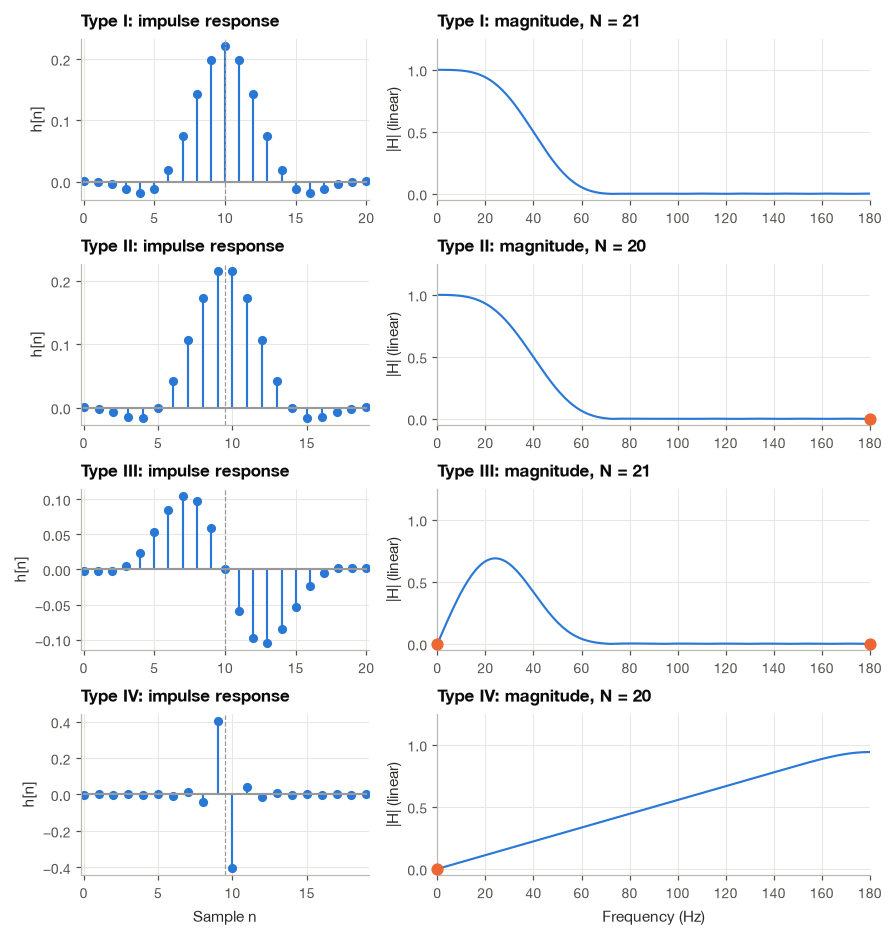

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(8, 8.4), gridspec_kw={"width_ratios": [1, 1.5]})
for row, (name, hk) in enumerate(examples.items()):
    n = np.arange(len(hk))
    ax = axes[row, 0]
    ax.stem(n, hk, linefmt=C[0], markerfmt="o", basefmt="0.6")
    ax.axvline((len(hk) - 1) / 2, color="0.6", ls="--", lw=0.8)
    ax.set(ylabel="h[n]", title=name.split(" (")[0] + ": impulse response")
    ax = axes[row, 1]
    f, H = signal.freqz(hk, worN=1024, fs=fs)
    ax.plot(f, np.abs(H), color=C[0])
    for fz in forced[name.split(" (")[0]]:
        ax.plot(fz, 0, "o", color=C[1], ms=7, clip_on=False, zorder=5)
    ax.set(ylabel="|H| (linear)", xlim=(0, fs / 2), ylim=(-0.05, 1.25),
           title=name.split(" (")[0] + f": magnitude, N = {len(hk)}")
axes[-1, 0].set_xlabel("Sample n")
axes[-1, 1].set_xlabel("Frequency (Hz)")
plt.show()

The dashed line in each impulse response marks the center of symmetry, $n = M/2$. For the two odd-length filters the center falls on a sample, for the even-length filters it falls halfway between two samples. The Type II low-pass filter looks almost identical to the Type I filter in the passband, but its response is pinned to zero at 180 Hz. That is harmless for a low-pass filter and fatal for a high-pass one.

(sec-9-1-5)=
## 9.1.5 Where the Zeros Lie

The mirror relation [(9.7)](#eq-9-7) also constrains the zeros. Suppose $H(z_0) = 0$ for some $z_0 \ne 0$. Evaluating [(9.7)](#eq-9-7) at $z = 1/z_0$ gives

$$
H(1/z_0) = \pm\, z_0^{M}\, H(z_0) = 0,
$$

so the reciprocal $1/z_0$ is also a zero. Because the coefficients are real, $H(z_0^*) = H(z_0)^* = 0$, so the conjugate is a zero as well. Combining the two facts, the zeros of a real linear-phase filter come in groups of four,

$$
\left\{ z_0,\; z_0^*,\; \frac{1}{z_0},\; \frac{1}{z_0^*} \right\},
$$

which are mirror images across the real axis and across the unit circle. Two special cases reduce the group. A zero *on* the unit circle satisfies $1/z_0^* = z_0$, so it needs only its conjugate partner; these are the zeros that carve the deep nulls in the stopband. A real zero off the circle pairs with its reciprocal, $\{r, 1/r\}$.

A consequence worth remembering is that a linear-phase filter with zeros off the unit circle always has some zeros *outside* it. It is therefore never minimum phase, the property of having all zeros inside the unit circle. A minimum-phase filter with the same magnitude response would have a shorter delay but a nonlinear phase, the trade-off discussed in Section 11.3.

The next cell computes the zeros of a 31-tap Type I low-pass filter and checks that the set is closed under the map $z \mapsto 1/z^*$.

In [7]:
h31 = signal.firwin(31, 40, fs=fs)            # Type I, M = 30, Hamming window
zeros = np.roots(h31)
mirror = 1 / np.conj(zeros)
pair_err = max(np.min(np.abs(zeros - zm)) for zm in mirror)
on_circle = np.abs(np.abs(zeros) - 1) < 1e-6

print(f"number of zeros               : {len(zeros)}")
print(f"zeros on the unit circle      : {on_circle.sum()}")
print(f"zeros inside / outside circle : {(np.abs(zeros) < 1 - 1e-6).sum()} / {(np.abs(zeros) > 1 + 1e-6).sum()}")
print(f"max distance from 1/z* to nearest zero: {pair_err:.2e}")
print("zeros inside the circle (upper half-plane and real axis):")
for z in zeros[(np.abs(zeros) < 1 - 1e-6) & (zeros.imag >= -1e-12)]:
    print(f"   |z| = {abs(z):.3f}, 1/|z| = {1 / abs(z):.3f}, angle = {np.angle(z) * fs / (2 * np.pi):5.1f} Hz")

number of zeros               : 30
zeros on the unit circle      : 20
zeros inside / outside circle : 5 / 5
max distance from 1/z* to nearest zero: 8.90e-15
zeros inside the circle (upper half-plane and real axis):
   |z| = 0.915, 1/|z| = 1.093, angle =  67.3 Hz
   |z| = 0.639, 1/|z| = 1.564, angle =  17.2 Hz
   |z| = 0.582, 1/|z| = 1.719, angle =   0.0 Hz


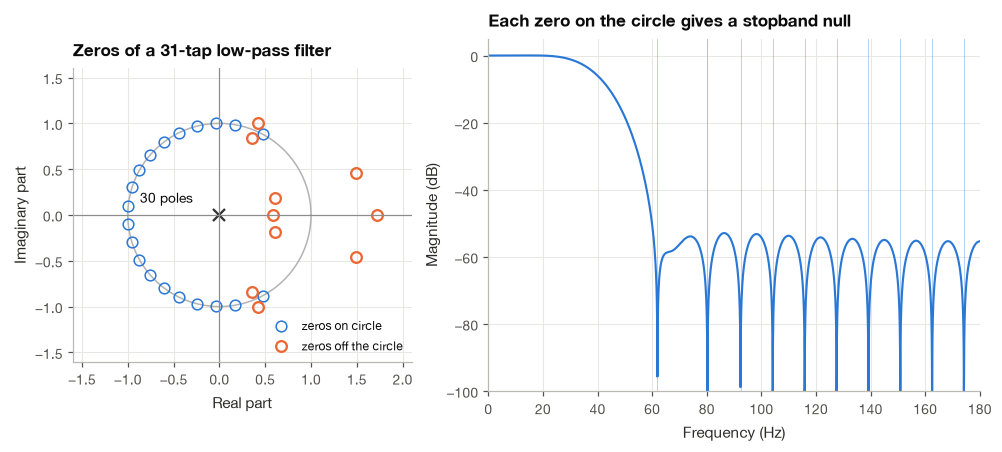

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.0), gridspec_kw={"width_ratios": [1, 1.45]})
ax = axes[0]
circle = np.exp(1j * np.linspace(0, 2 * np.pi, 400))
ax.plot(circle.real, circle.imag, color="0.7", lw=1)
ax.plot(zeros[on_circle].real, zeros[on_circle].imag, "o", mfc="none", mec=C[0], ms=7, label="zeros on circle")
ax.plot(zeros[~on_circle].real, zeros[~on_circle].imag, "o", mfc="none", mec=C[1], ms=7, mew=1.5,
        label="zeros off the circle")
ax.plot(0, 0, "x", color="0.2", ms=8, mew=1.5)
ax.annotate("30 poles", (0, 0), textcoords="offset points", xytext=(-52, 8), fontsize=9)
ax.axhline(0, color="0.55", lw=0.8)
ax.axvline(0, color="0.55", lw=0.8)
ax.set(xlim=(-1.6, 2.1), ylim=(-1.6, 1.6), xlabel="Real part", ylabel="Imaginary part",
       title="Zeros of a 31-tap low-pass filter")
ax.set_aspect("equal")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
f, H = signal.freqz(h31, worN=4096, fs=fs)
ax.plot(f, 20 * np.log10(np.abs(H) + 1e-12), color=C[0])
f_null = np.angle(zeros[on_circle & (zeros.imag > 0)]) * fs / (2 * np.pi)
for fn in f_null:
    ax.axvline(fn, color=C[0], lw=0.6, alpha=0.35)
ax.set(xlim=(0, fs / 2), ylim=(-100, 5), xlabel="Frequency (Hz)", ylabel="Magnitude (dB)",
       title="Each zero on the circle gives a stopband null")
plt.show()

Twenty of the thirty zeros lie on the unit circle. The other ten (orange) form two complex quadruplets and one real reciprocal pair, exactly as predicted: each zero inside the circle at radius $r$ has a partner outside at radius $1/r$ on the same ray. The real pair and the quadruplet at about 17 Hz shape the passband, while the quadruplet at about 67 Hz sits just off the circle, which is why the response shows a shoulder rather than a deep null near 65 Hz. Each thin vertical line on the right marks the angle of one unit-circle zero, converted to hertz with $f = \Omega f_s/(2\pi)$, and each coincides with a null of the magnitude response.

(sec-9-1-6)=
## 9.1.6 Group Delay and Implementation

Since the phase of every linear-phase filter is $\beta - \Omega M/2$ (plus jumps of $\pi$ at sign changes of $A$), its group delay is

(eq-9-8)=
\begin{equation*}
\tau_g = -\frac{d}{d\Omega}\left(\beta - \frac{\Omega M}{2}\right) = \frac{M}{2}\ \text{samples} = \frac{M}{2 f_s}\ \text{seconds}. \tag{9.8}
\end{equation*}

For a Type I filter, $M/2$ is an integer and we can remove the delay exactly by discarding the first $M/2$ output samples. For Types II and IV the delay is a half-integer, for example 9.5 samples for a 20-tap filter. That half sample cannot be removed by shifting indices; it has to be interpolated ([Section 9.3](../ch09_sampling/index.md)) or tolerated. This is one practical reason to prefer odd-length filters whenever we intend to align the filtered signal with the original, for example to compare detected R-peak times with reference annotations.

`scipy.signal.group_delay` evaluates $-d\varphi/d\Omega$ numerically. We evaluate it only in the passband, because at the exact zeros of $H$ the phase is undefined.

In [9]:
f_pass = np.linspace(0, 35, 50)
for name, hk in [("Type I, N = 21", examples["Type I (N = 21, symmetric)"]),
                 ("Type II, N = 20", examples["Type II (N = 20, symmetric)"]),
                 ("Type I, N = 31", h31)]:
    _, gd = signal.group_delay((hk, 1.0), w=f_pass, fs=fs)
    M = len(hk) - 1
    print(f"{name:16s}: group delay {gd.min():.3f} to {gd.max():.3f} samples "
          f"(M/2 = {M / 2:.1f}, i.e. {1e3 * M / (2 * fs):.1f} ms)")

Type I, N = 21  : group delay 10.000 to 10.000 samples (M/2 = 10.0, i.e. 27.8 ms)
Type II, N = 20 : group delay 9.500 to 9.500 samples (M/2 = 9.5, i.e. 26.4 ms)
Type I, N = 31  : group delay 15.000 to 15.000 samples (M/2 = 15.0, i.e. 41.7 ms)


### Implementing an FIR filter efficiently

The direct form [(9.1)](#eq-9-1) costs $N = M + 1$ multiplications and $M$ additions per output sample. Symmetry offers a free saving. For a Type I filter, the coefficients at distances $k$ and $M - k$ from the newest sample are equal, so we may add the two input samples first and multiply once:

(eq-9-9)=
\begin{equation*}
y[n] = h[M/2]\,x[n - M/2] + \sum_{k=0}^{M/2-1} h[k]\,\big(x[n-k] + x[n-M+k]\big). \tag{9.9}
\end{equation*}

This **folded** structure needs $M/2 + 1$ multiplications per sample, roughly half. For very long filters, such as the 2000-tap ECG band-pass filter we will meet in Section 14.2, it is faster still to convolve in the frequency domain with the FFT (`scipy.signal.fftconvolve` or `scipy.signal.oaconvolve`), whose cost per output sample grows only logarithmically with $N$. All of these give the same numbers up to rounding.

In [10]:
def fir_folded(h, x):
    """Type I FIR filter using the folded structure of equation (14.9)."""
    M = len(h) - 1
    xp = np.r_[np.zeros(M), x]                 # zero initial conditions
    L = len(x)
    y = h[M // 2] * xp[M - M // 2 : M - M // 2 + L]
    for k in range(M // 2):
        y = y + h[k] * (xp[M - k : M - k + L] + xp[k : k + L])
    return y


x = rng.normal(size=5000)
y_ref = signal.lfilter(h31, 1.0, x)
y_fold = fir_folded(h31, x)
y_fft = signal.fftconvolve(x, h31)[: len(x)]
print(f"max |folded - lfilter|      = {np.max(np.abs(y_fold - y_ref)):.2e}")
print(f"max |fftconvolve - lfilter| = {np.max(np.abs(y_fft - y_ref)):.2e}")
print(f"multiplications per sample: direct {len(h31)}, folded {len(h31) // 2 + 1}")

max |folded - lfilter|      = 4.44e-16
max |fftconvolve - lfilter| = 1.11e-15
multiplications per sample: direct 31, folded 16


(sec-9-1-7)=
## 9.1.7 FIR versus IIR

Linear phase and guaranteed stability come at a price, and the price is length. To see how large it is, consider a realistic specification for an ECG low-pass filter at $f_s = 360$ Hz: pass everything up to 40 Hz with a ripple of at most $\delta_p = 0.01$ (about 0.17 dB), and attenuate everything above 50 Hz by at least 40 dB ($\delta_s = 0.01$). The ripple and attenuation conventions are those of [Section 8.1](../ch13_filter_fundamentals/index.md). We ask SciPy for the smallest IIR orders that meet this specification, and find the shortest equiripple FIR filter (the optimal design of Section 14.3) by increasing the length until the specification is met.

In [11]:
f_pass_edge, f_stop_edge = 40.0, 50.0
delta_p = delta_s = 0.01
Ap = 20 * np.log10((1 + delta_p) / (1 - delta_p))     # passband ripple (dB)
As = -20 * np.log10(delta_s)                          # stopband attenuation (dB)


def meets_spec(b, a=1.0):
    """True if the filter (b, a) satisfies the passband and stopband tolerances."""
    f, H = signal.freqz(b, a, worN=8192, fs=fs)
    pb, sb = np.abs(H[f <= f_pass_edge]), np.abs(H[f >= f_stop_edge])
    return np.max(np.abs(pb - 1)) <= delta_p and np.max(sb) <= delta_s


n_fir = next(n for n in range(30, 200)
             if meets_spec(signal.remez(n, [0, f_pass_edge, f_stop_edge, fs / 2], [1, 0], fs=fs)))
h_eq = signal.remez(n_fir, [0, f_pass_edge, f_stop_edge, fs / 2], [1, 0], fs=fs)

rows = [{"design": "FIR equiripple", "order": n_fir - 1, "mult./sample (approx.)": n_fir // 2 + n_fir % 2,
         "group delay": "constant"}]
for name, ordfun in [("IIR Butterworth", signal.buttord), ("IIR Chebyshev I", signal.cheb1ord),
                     ("IIR elliptic", signal.ellipord)]:
    order, _ = ordfun(f_pass_edge, f_stop_edge, Ap, As, fs=fs)
    rows.append({"design": name, "order": order, "mult./sample (approx.)": 5 * int(np.ceil(order / 2)),
                 "group delay": "frequency dependent"})
print(f"Specification: Ap = {Ap:.2f} dB, As = {As:.0f} dB, transition 40-50 Hz at fs = {fs:.0f} Hz")
print(pd.DataFrame(rows).to_string(index=False))

Specification: Ap = 0.17 dB, As = 40 dB, transition 40-50 Hz at fs = 360 Hz
         design  order  mult./sample (approx.)         group delay
 FIR equiripple     73                      37            constant
IIR Butterworth     26                      65 frequency dependent
IIR Chebyshev I     10                      25 frequency dependent
   IIR elliptic      6                      15 frequency dependent


The equiripple FIR filter needs an order roughly twelve times that of the elliptic filter. Even after the folding trick, it performs a few times more multiplications per sample than the elliptic filter implemented as second-order sections (five multiplications per section). On a modern computer this is irrelevant for a single ECG channel. On a battery-powered patch that filters several channels at high rates, it can matter.

The more important difference is the delay. The next figure compares the group delay of the two designs across the passband.

In [12]:
order_e, wn_e = signal.ellipord(f_pass_edge, f_stop_edge, Ap, As, fs=fs)
b_e, a_e = signal.ellip(order_e, Ap, As, wn_e, fs=fs)
f_gd = np.linspace(0.1, 39.9, 400)
_, gd_fir = signal.group_delay((h_eq, 1.0), w=f_gd, fs=fs)
_, gd_iir = signal.group_delay((b_e, a_e), w=f_gd, fs=fs)
print(f"FIR group delay      : {1e3 * gd_fir.min() / fs:.1f} to {1e3 * gd_fir.max() / fs:.1f} ms")
print(f"Elliptic group delay : {1e3 * gd_iir.min() / fs:.1f} to {1e3 * gd_iir.max() / fs:.1f} ms "
      f"(at 5 Hz: {1e3 * np.interp(5, f_gd, gd_iir) / fs:.1f} ms, at 35 Hz: {1e3 * np.interp(35, f_gd, gd_iir) / fs:.1f} ms)")

FIR group delay      : 101.4 to 101.4 ms
Elliptic group delay : 11.2 to 92.2 ms (at 5 Hz: 11.5 ms, at 35 Hz: 33.3 ms)


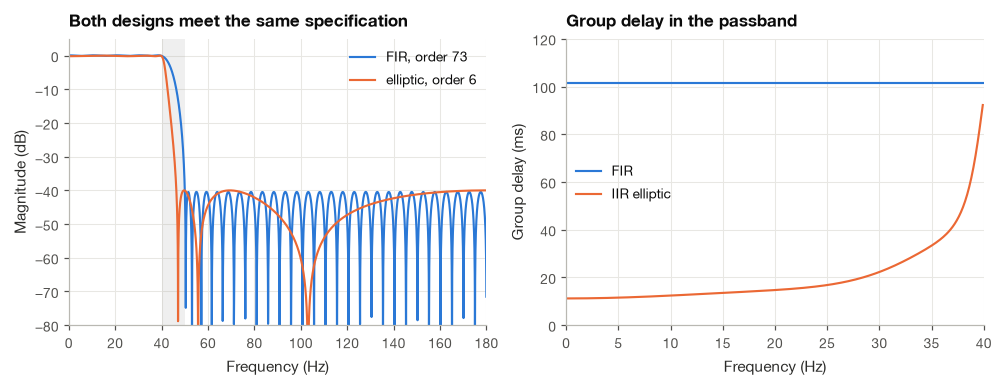

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
ax = axes[0]
for (b, a), label, col in [((h_eq, 1.0), f"FIR, order {n_fir - 1}", C[0]),
                            ((b_e, a_e), f"elliptic, order {order_e}", C[1])]:
    f, H = signal.freqz(b, a, worN=4096, fs=fs)
    ax.plot(f, 20 * np.log10(np.abs(H) + 1e-12), color=col, label=label)
ax.axvspan(f_pass_edge, f_stop_edge, color="0.6", alpha=0.15, lw=0)
ax.set(xlim=(0, fs / 2), ylim=(-80, 5), xlabel="Frequency (Hz)", ylabel="Magnitude (dB)",
       title="Both designs meet the same specification")
ax.legend(loc="upper right")

ax = axes[1]
ax.plot(f_gd, 1e3 * gd_fir / fs, color=C[0], label="FIR")
ax.plot(f_gd, 1e3 * gd_iir / fs, color=C[1], label="IIR elliptic")
ax.set(xlim=(0, 40), ylim=(0, 120), xlabel="Frequency (Hz)", ylabel="Group delay (ms)",
       title="Group delay in the passband")
ax.legend(loc="center left")
plt.show()

The FIR filter delays every passband frequency by the same 101 ms. The elliptic filter is faster on average, but its delay climbs from about 11 ms at low frequencies to 33 ms at 35 Hz and 92 ms at the band edge, so the slow and fast components of a QRS complex are pulled apart in time. The table below gathers the trade-offs.

| Property | FIR | IIR |
|---|---|---|
| Stability | always stable (all poles at $z = 0$) | must be checked; poles near the unit circle are sensitive to rounding |
| Phase | exactly linear when coefficients are symmetric | nonlinear; zero phase only offline, by forward-backward filtering |
| Order for a sharp transition | high (tens to thousands of taps) | low (typically 4 to 12) |
| Delay | $M/2$ samples, can be long | short, but frequency dependent |
| Sensitivity to coefficient rounding | low; symmetry survives rounding | can be high in direct form; use second-order sections |
| Design | linear problem (windows, least squares, minimax) | via analog prototypes and the bilinear transform |

For offline analysis of a recorded ECG or EEG, the phase advantage of FIR can also be obtained from an IIR filter by running it forward and then backward with `scipy.signal.filtfilt`, as described in Chapter 15. For real-time systems such as bedside arrhythmia alarms, closed-loop neurostimulators or a wearable that must react within a heartbeat, forward-backward filtering is impossible and the choice is between a constant delay (FIR) and a frequency-dependent one (IIR). My own rule of thumb is simple: if anyone will look at the shape of the waveform or measure intervals on it, I use a linear-phase FIR filter (or zero-phase filtering offline); if only a detection or a rate is needed in real time, a low-order IIR filter is usually the better engineering choice.

(sec-9-1-8)=
## 9.1.8 Applied Example: Low-Pass Filtering an ECG Without Distortion

We now put the theory to work on a real ECG. The goal is not to build a complete cleaning pipeline (that is the subject of [Chapter 12](../ch18_ecg_preprocessing/index.md), and muscle noise in particular is treated in [Section 18.3](../ch18_ecg_preprocessing/index.md)), but to watch what a linear-phase filter does to the timing and the shape of the beats.

### Step 1: Load a clean ECG and build a realistic noisy version

Ten seconds of lead MLII from record 100 of the MIT-BIH Arrhythmia Database {cite:p}`moody2001,goldberger2000` serve as a clean reference, with the cardiologists' beat annotations. To create a realistic noisy version I add two kinds of interference. The first is real muscle-artifact noise from the MIT-BIH Noise Stress Test Database {cite:p}`moody1984`, scaled to a signal-to-noise ratio of 12 dB. The second is 0.2 mV of 60 Hz power-line hum, the mains frequency where the MIT-BIH recordings were made.

In [14]:
rec = wfdb.rdrecord("../data/mitdb/100", sampfrom=0, sampto=3600, channels=[0])
ecg_clean = rec.p_signal[:, 0]
ann = wfdb.rdann("../data/mitdb/100", "atr", sampfrom=0, sampto=3600)
beats = np.array([s for s, sym in zip(ann.sample, ann.symbol) if sym in "NAV"])
t = np.arange(len(ecg_clean)) / fs

muscle = wfdb.rdrecord("../data/nstdb/ma", sampfrom=0, sampto=3600, channels=[0]).p_signal[:, 0]
muscle = muscle - muscle.mean()
snr_db = 12.0
muscle *= np.sqrt(np.var(ecg_clean) / (np.var(muscle) * 10 ** (snr_db / 10)))
hum = 0.2 * np.sin(2 * np.pi * 60 * t + 0.3)                    # 0.2 mV at 60 Hz
ecg_noisy = ecg_clean + muscle + hum

f_m, P_m = signal.welch(muscle, fs=fs, nperseg=1024)
frac_above_40 = np.sum(P_m[f_m > 40]) / np.sum(P_m)
print(f"Beats in the 10 s window       : {len(beats)}")
print(f"Muscle noise RMS               : {1e3 * muscle.std():.1f} uV")
print(f"Muscle noise power above 40 Hz : {100 * frac_above_40:.0f} %")

Beats in the 10 s window       : 13
Muscle noise RMS               : 42.8 uV
Muscle noise power above 40 Hz : 4 %


The last line deserves attention before we design anything. Only a small fraction of this muscle noise lies above 40 Hz; most of it shares the band of the ECG itself. A low-pass filter will remove the hum completely, but it can remove only the high-frequency tail of the muscle noise. Knowing this in advance keeps our expectations honest.

### Step 2: Design the filter and check the specification

I use an equiripple low-pass filter with the specification of [Section 9.1.7](#sec-9-1-7) (passband to 40 Hz, stopband from 50 Hz, $\delta_p = \delta_s = 0.01$). The minimum length found there was 74 taps, an even number and therefore a Type II filter with a half-sample delay. I add one tap to obtain a Type I filter with 75 taps, so that the delay $M/2 = 37$ samples is a whole number.

In [15]:
h_lp = signal.remez(75, [0, f_pass_edge, f_stop_edge, fs / 2], [1, 0], fs=fs)
delay = (len(h_lp) - 1) // 2
print(f"Filter: {len(h_lp)} taps, symmetric: {np.allclose(h_lp, h_lp[::-1])}, spec met: {meets_spec(h_lp)}")
print(f"Delay M/2 = {delay} samples = {1e3 * delay / fs:.1f} ms")
f_h, H_h = signal.freqz(h_lp, worN=[60.0], fs=fs)
print(f"Attenuation of the 60 Hz hum: {-20 * np.log10(abs(H_h[0])):.1f} dB")

Filter: 75 taps, symmetric: True, spec met: True
Delay M/2 = 37 samples = 102.8 ms
Attenuation of the 60 Hz hum: 43.2 dB


### Step 3: Filter causally and look at the output

We run the filter with `lfilter`, exactly as a real-time device would: each output sample uses only present and past inputs.

In [16]:
ecg_causal = signal.lfilter(h_lp, 1.0, ecg_noisy)
ecg_aligned = np.r_[ecg_causal[delay:], np.full(delay, np.nan)]   # remove the M/2 delay (see below)

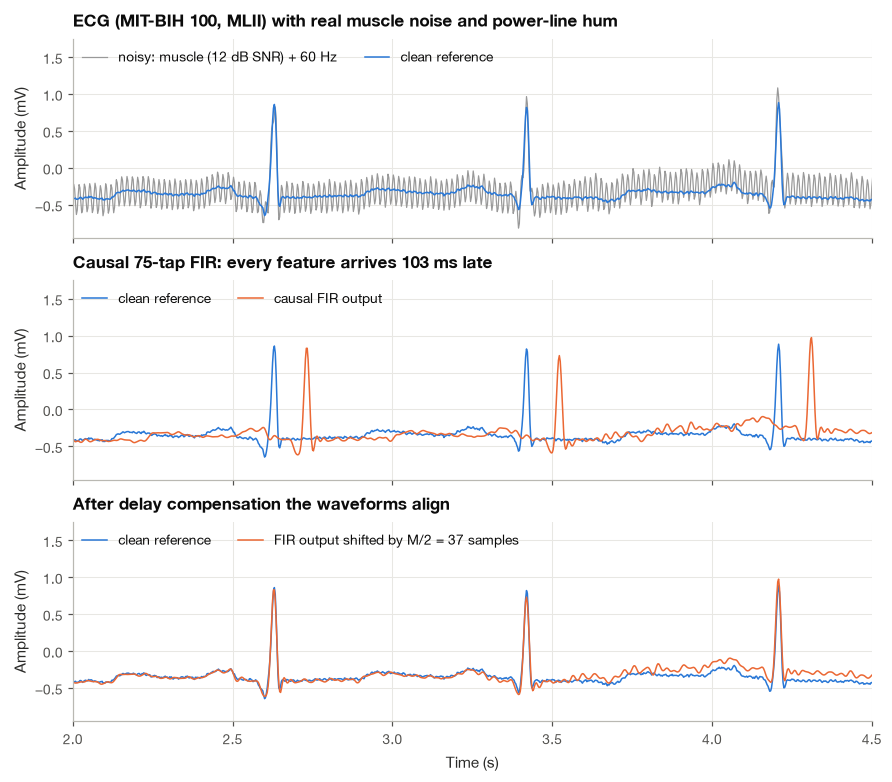

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(8, 7.0), sharex=True)
ax = axes[0]
ax.plot(t, ecg_noisy, color="0.6", lw=0.8, label="noisy: muscle (12 dB SNR) + 60 Hz")
ax.plot(t, ecg_clean, color=C[0], lw=1.0, label="clean reference")
ax.set(ylabel="Amplitude (mV)", title="ECG (MIT-BIH 100, MLII) with real muscle noise and power-line hum")

ax = axes[1]
ax.plot(t, ecg_clean, color=C[0], lw=1.0, label="clean reference")
ax.plot(t, ecg_causal, color=C[1], lw=1.0, label="causal FIR output")
ax.set(ylabel="Amplitude (mV)", title=f"Causal 75-tap FIR: every feature arrives {1e3 * delay / fs:.0f} ms late")

ax = axes[2]
ax.plot(t, ecg_clean, color=C[0], lw=1.0, label="clean reference")
ax.plot(t, ecg_aligned, color=C[1], lw=1.0, label=f"FIR output shifted by M/2 = {delay} samples")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="After delay compensation the waveforms align")
for ax in axes:
    ax.set_ylim(-0.95, 1.75)
    ax.legend(loc="upper left", ncol=2)
axes[-1].set_xlim(2.0, 4.5)
plt.show()

The top panel shows how badly the hum and the muscle noise obscure the baseline. In the middle panel the hum is gone and the trace is much smoother, but the output is the ECG translated to the right by 37 samples (102.8 ms). Every feature moves by the same amount: the R peaks, the P waves and the T waves, because every frequency in the passband sees the same delay. The shape of the QRS complex is preserved, which is precisely the promise of linear phase.

### Step 4: Compensate the delay

Because the delay is a whole number of samples, compensation is a single slice: we discard the first $M/2$ output samples, which we already did in the code of Step 3 when computing `ecg_aligned`, and pad the end with `NaN` so that the arrays keep their length. In the bottom panel the filtered ECG now lies on top of the reference, apart from the slow muscle-noise wobble that no 40 Hz low-pass filter can remove. For offline work the same result can be obtained in one call with `scipy.signal.filtfilt(h_lp, 1.0, x)` or by convolving with `mode="same"`, at the cost of running the filter on both sides of each sample.

### Step 5: Check the result quantitatively

To quantify timing, we locate each R peak as the maximum within $\pm 50$ ms of the reference annotation in the clean signal, and then search for the corresponding maximum in the filtered signals, extending the window by the filter delay for the causal output. We also compute the root-mean-square difference between each signal and the clean ECG.

In [18]:
def peak_near(x, centers, before, after):
    """Index of the maximum of x within [c - before, c + after] for each center c."""
    return np.array([c - before + np.nanargmax(x[c - before : c + after]) for c in centers])


win = int(0.05 * fs)
inner = beats[(beats > win + 1) & (beats < len(ecg_clean) - win - delay - 1)]
r_clean = peak_near(ecg_clean, inner, win, win)
r_causal = peak_near(ecg_causal, inner, win, win + delay)
r_aligned = peak_near(ecg_aligned, inner, win, win)

valid = slice(delay, len(ecg_clean) - delay)


def rms_uv(d):
    """RMS of a difference signal over the valid range, in microvolts."""
    return 1e3 * np.sqrt(np.nanmean(d[valid] ** 2))


print(f"R-peak shift, causal FIR : mean {np.mean(r_causal - r_clean):+.2f} samples, "
      f"range {np.min(r_causal - r_clean):+d} to {np.max(r_causal - r_clean):+d}")
print(f"R-peak shift, aligned    : mean {np.mean(r_aligned - r_clean):+.2f} samples, "
      f"range {np.min(r_aligned - r_clean):+d} to {np.max(r_aligned - r_clean):+d}")
print(f"RMS error vs clean ECG   : noisy {rms_uv(ecg_noisy - ecg_clean):.0f} uV, "
      f"causal {rms_uv(ecg_causal - ecg_clean):.0f} uV, aligned {rms_uv(ecg_aligned - ecg_clean):.0f} uV")
ecg_clean_filt = np.r_[signal.lfilter(h_lp, 1.0, ecg_clean)[delay:], np.full(delay, np.nan)]
print(f"Error the filter adds to the clean ECG itself: {rms_uv(ecg_clean_filt - ecg_clean):.0f} uV")

R-peak shift, causal FIR : mean +36.75 samples, range +36 to +37
R-peak shift, aligned    : mean -0.25 samples, range -1 to +0
RMS error vs clean ECG   : noisy 148 uV, causal 246 uV, aligned 46 uV
Error the filter adds to the clean ECG itself: 16 uV


The numbers tell the whole story. The causal output shifts every R peak by 36 or 37 samples, and after compensation the peaks agree with the reference to within a sample. The compensated output reduces the RMS error from about 148 µV to 46 µV; what remains is almost entirely the in-band muscle noise (43 µV RMS before filtering), plus the 16 µV that the filter removes from the sharp QRS complexes of the clean ECG itself. The uncompensated output, on the other hand, is *worse* than doing nothing at all, simply because it is misaligned. In my experience, a forgotten filter delay is the single most common bug in biomedical signal pipelines.

```{important}
A causal FIR filter of length $N$ delays its output by $(N-1)/2$ samples. Whenever filtered signals are compared with annotations, other channels, or signals filtered differently (for example ECG R peaks and PPG pulse arrival in [Section 13.2](../ch13_filter_fundamentals/index.md)), compensate this delay, and prefer odd $N$ so that the shift is a whole number of samples.
```

## Summary

An FIR filter forms each output sample as a finite weighted sum of input samples, so its impulse response is its list of coefficients and all of its poles sit at the origin: it is always stable. When the coefficients are symmetric or antisymmetric about their midpoint, the frequency response factors into a real amplitude function times the pure delay term $e^{-j\Omega M/2}$, as we derived step by step for Type I in equation [(9.6)](#eq-9-6). Every frequency is then delayed by the same $M/2$ samples, waveforms pass through undistorted, and the delay can be removed exactly when $M$ is even. The four types differ in the zeros they are forced to have: antisymmetric filters always block DC, and Types II and III always block the Nyquist frequency, which is why a high-pass filter must be Type I. The mirror relation $H(z) = \pm z^{-M}H(z^{-1})$ makes the zeros appear in reciprocal quadruplets or on the unit circle.

Compared with IIR filters, linear-phase FIR filters need far higher orders for the same sharp transition and introduce longer delays, but their delay is constant and known. On a real ECG, a 75-tap low-pass filter shifted every feature by 102.8 ms and nothing else, and one index shift realigned it with the reference. The next two sections answer the question this section left open: given a specification, how do we choose the coefficients? Section 14.2 truncates the ideal impulse response with a window, and Section 14.3 poses design as an optimization problem.

## Exercises

1. Show that the filter $h = [1, -2, 1]$ (the second difference) has linear phase. Which type is it? Derive $H(e^{j\Omega})$ in the form $e^{-j\Omega}A(\Omega)$, sketch $A(\Omega)$, and explain why the filter can be used to enhance the QRS complex relative to the T wave.
2. Repeat Steps 1 to 5 of [Section 9.1.3](#sec-9-1-3) for a Type II filter (odd $M$, symmetric) and confirm the amplitude function stated in Section 9.1.4. Then verify your result numerically for a random symmetric filter of length 12, in the same way as the code cell after Example 9.1.1.
3. A Type III filter has zeros at $z = 0.5\,e^{j\pi/3}$ among others. List the other zeros that must be present. What is the smallest possible order of such a filter, and what are its coefficients (up to a scale factor)? Check with `np.poly`.
4. Use the mirror relation [(9.7)](#eq-9-7) to prove that the group delay of a linear-phase filter is $M/2$ at every frequency where $H(e^{j\Omega}) \neq 0$, without computing $A(\Omega)$. (Hint: write $H(e^{j\Omega}) = |H|e^{j\varphi}$ on both sides of [(9.7)](#eq-9-7) with $z = e^{j\Omega}$.)
5. Using the specification of [Section 9.1.7](#sec-9-1-7), design the Butterworth filter returned by `signal.buttord` and apply it causally to the noisy ECG of Section 9.1.8. Try to align the output with the clean ECG by a constant shift chosen to maximize the cross-correlation. How large is the remaining RMS error compared with the FIR result, and where in the beat is it concentrated?
6. Write a function that classifies an arbitrary coefficient vector as Type I, II, III, IV or "not linear phase", and test it on the filters `signal.firwin(41, [5, 15], pass_zero=False, fs=360)`, `signal.remez(30, [0, 0.4], [1], type="differentiator", fs=1)`, `signal.remez(31, [0.05, 0.45], [1], type="hilbert", fs=1)` and `signal.butter(4, 0.2)[0]` (the numerator of a Butterworth filter). Comment on the last case.

## Further Reading

Generalized linear phase and the four FIR types are treated rigorously in {cite:t}`oppenheim2010` (Chapter 4), including the zero-location argument, and {cite:t}`proakis2007` (Chapter 10) gives the corresponding amplitude functions in a form convenient for design. {cite:t}`lyons2010` discusses efficient FIR implementations, including the folded structure, from a practitioner's viewpoint, and {cite:t}`smith1997` contrasts FIR and IIR filters with many intuitive examples. For the role of filter phase in ECG measurements, see the recommendations of {cite:t}`kligfield2007`.